<a href="https://colab.research.google.com/github/Farelldorea/kelompok_kka/blob/main/PraktekKelompok.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")

uploaded = files.upload()
nama_file = next(iter(uploaded))

df = pd.read_csv(nama_file)
df.columns = df.columns.str.strip()

print("Ukuran data:", df.shape)
display(df.head())

Saving supermarket_sales.csv to supermarket_sales (1).csv
Ukuran data: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [2]:
print("Informasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe().T)

print("\nData kosong:")
print(df.isnull().sum())

print("\nJumlah duplikat:", df.duplicated().sum())

df = df.drop_duplicates().copy()

df["Date"] = pd.to_datetime(
    df["Date"], errors="coerce", format="mixed"
)

kolom_penting = [
    "Invoice ID", "City", "Product line",
    "Unit price", "Quantity", "Total",
    "Date", "Rating"
]

df = df.dropna(subset=kolom_penting).copy()

print("\nUkuran data setelah dibersihkan:", df.shape)


Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross 

,count,mean,std,min,25%,50%,75%,max
Unit price,1000.0,55.672130,2.649463e+01,10.080000,32.875000,55.230000,77.935000,99.960000
Quantity,1000.0,5.510000,2.923431e+00,1.000000,3.000000,5.000000,8.000000,10.000000
Tax 5%,1000.0,15.379369,1.170883e+01,0.508500,5.924875,12.088000,22.445250,49.650000
Total,1000.0,322.966749,2.458853e+02,10.678500,124.422375,253.848000,471.350250,1042.650000
cogs,1000.0,307.587380,2.341765e+02,10.170000,118.497500,241.760000,448.905000,993.000000
gross margin percentage,1000.0,4.761905,6.131498e-14,4.761905,4.761905,4.761905,4.761905,4.761905
gross income,1000.0,15.379369,1.170883e+01,0.508500,5.924875,12.088000,22.445250,49.650000
Rating,1000.0,6.972700,1.718580e+00,4.000000,5.500000,7.000000,8.500000,10.000000



Data kosong:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Jumlah duplikat: 0

Ukuran data setelah dibersihkan: (1000, 17)


In [3]:
total_penjualan = df["Total"].sum()
rata_transaksi = df["Total"].mean()
median_transaksi = df["Total"].median()
std_transaksi = df["Total"].std()
rating_rata = df["Rating"].mean()

penjualan_kategori = df.groupby("Product line")["Total"].sum()
penjualan_kota = df.groupby("City")["Total"].sum()

kategori_terlaris = penjualan_kategori.idxmax()
kategori_terendah = penjualan_kategori.idxmin()
kota_teratas = penjualan_kota.idxmax()

print("Jumlah transaksi:", len(df))
print(f"Total penjualan: {total_penjualan:,.2f}")
print(f"Rata-rata transaksi: {rata_transaksi:,.2f}")
print(f"Median transaksi: {median_transaksi:,.2f}")
print(f"Standar deviasi: {std_transaksi:,.2f}")
print(f"Rating rata-rata: {rating_rata:.2f}/10")

print("\nInterpretasi:")
print(f"1. Total penjualan mencapai {total_penjualan:,.2f}.")
print(f"2. Rata-rata transaksi adalah {rata_transaksi:,.2f}.")
print(f"3. Kategori terlaris adalah {kategori_terlaris}.")
print(f"4. Kategori penjualan terendah adalah {kategori_terendah}.")
print(f"5. Kota dengan penjualan tertinggi adalah {kota_teratas}.")


Jumlah transaksi: 1000
Total penjualan: 322,966.75
Rata-rata transaksi: 322.97
Median transaksi: 253.85
Standar deviasi: 245.89
Rating rata-rata: 6.97/10

Interpretasi:
1. Total penjualan mencapai 322,966.75.
2. Rata-rata transaksi adalah 322.97.
3. Kategori terlaris adalah Food and beverages.
4. Kategori penjualan terendah adalah Health and beauty.
5. Kota dengan penjualan tertinggi adalah Naypyitaw.


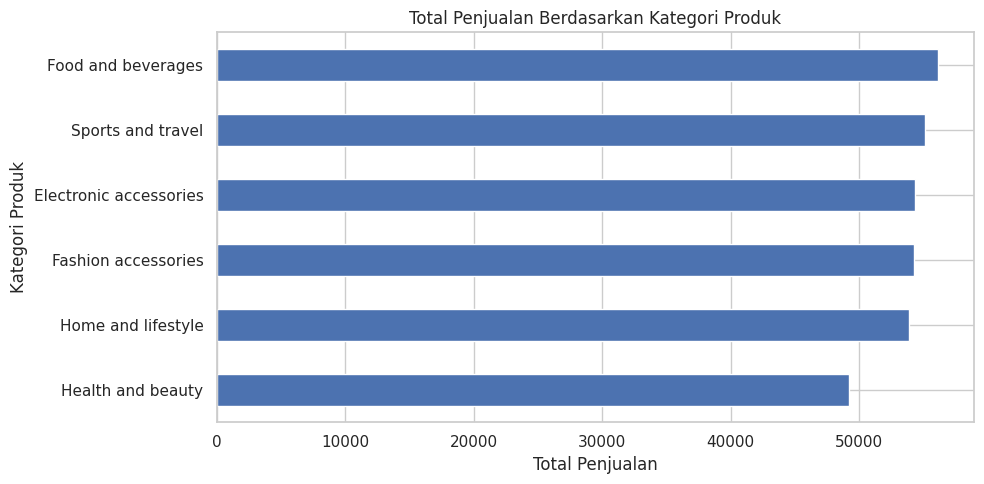

Insight:
Kategori terlaris adalah Food and beverages.
Kategori terendah adalah Health and beauty.
Kategori dengan penjualan rendah perlu dievaluasi dari sisi permintaan dan promosi.


In [5]:
plt.figure(figsize=(10, 5))

penjualan_kategori.sort_values().plot(kind="barh")

plt.title("Total Penjualan Berdasarkan Kategori Produk")
plt.xlabel("Total Penjualan")
plt.ylabel("Kategori Produk")
plt.tight_layout()
plt.show()

print("Insight:")
print(f"Kategori terlaris adalah {kategori_terlaris}.")
print(f"Kategori terendah adalah {kategori_terendah}.")
print("Kategori dengan penjualan rendah perlu dievaluasi dari sisi permintaan dan promosi.")


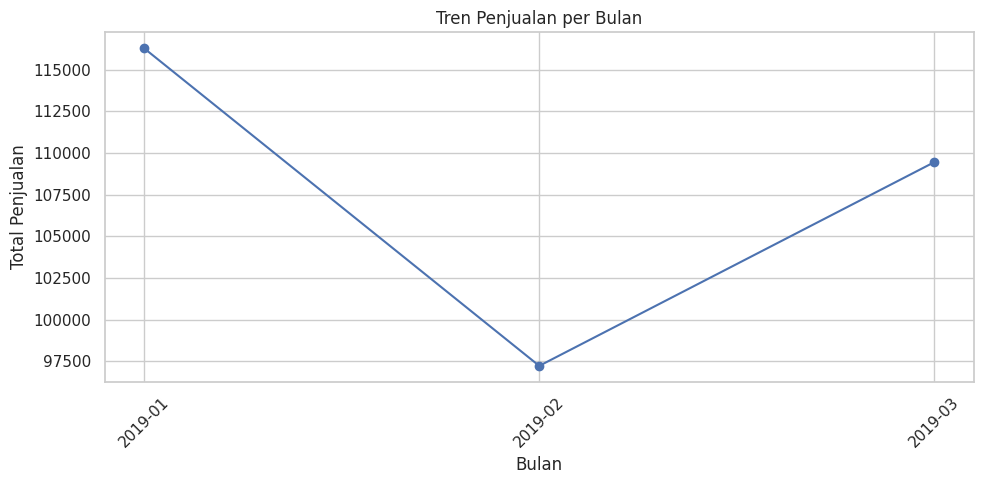

Insight:
Bulan dengan penjualan tertinggi: 2019-01
Bulan dengan penjualan terendah: 2019-02
Tren ini dapat membantu menentukan waktu promosi.


In [6]:
df["Bulan"] = df["Date"].dt.to_period("M").astype(str)

penjualan_bulanan = (
    df.groupby("Bulan")["Total"].sum().sort_index()
)

plt.figure(figsize=(10, 5))
plt.plot(
    penjualan_bulanan.index,
    penjualan_bulanan.values,
    marker="o"
)

plt.title("Tren Penjualan per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Total Penjualan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Insight:")
print("Bulan dengan penjualan tertinggi:", penjualan_bulanan.idxmax())
print("Bulan dengan penjualan terendah:", penjualan_bulanan.idxmin())
print("Tren ini dapat membantu menentukan waktu promosi.")


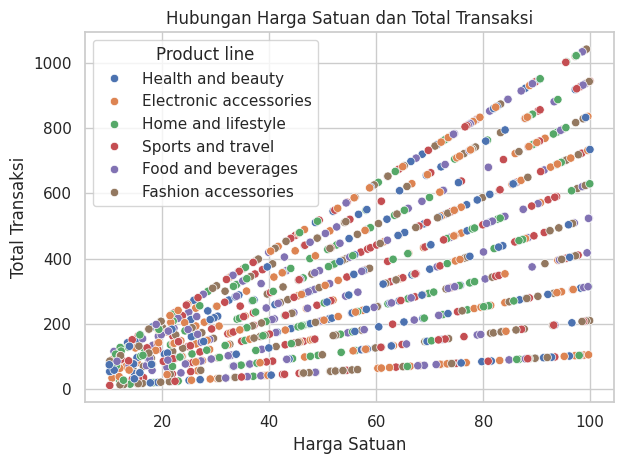

Korelasi harga dan total transaksi: 0.634
Insight: korelasi menunjukkan kekuatan hubungan linear antara kedua variabel.


In [8]:
sns.scatterplot(
    data=df,
    x="Unit price",
    y="Total",
    hue="Product line"
)

plt.title("Hubungan Harga Satuan dan Total Transaksi")
plt.xlabel("Harga Satuan")
plt.ylabel("Total Transaksi")
plt.tight_layout()
plt.show()

korelasi = df["Unit price"].corr(df["Total"])

print("Korelasi harga dan total transaksi:", round(korelasi, 3))
print("Insight: korelasi menunjukkan kekuatan hubungan linear antara kedua variabel.")


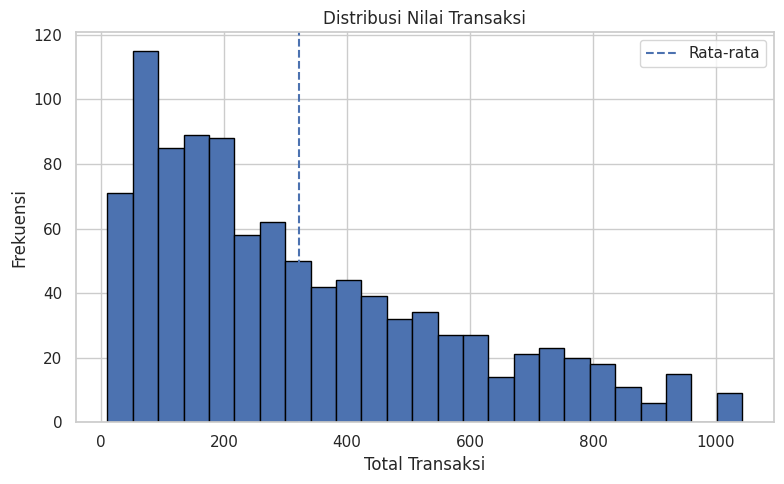

Insight:
Rata-rata transaksi: 322.97
Median transaksi: 253.85
Histogram memperlihatkan sebaran nilai transaksi.


In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["Total"], bins=25, edgecolor="black")
plt.axvline(
    rata_transaksi,
    linestyle="--",
    label="Rata-rata"
)

plt.title("Distribusi Nilai Transaksi")
plt.xlabel("Total Transaksi")
plt.ylabel("Frekuensi")
plt.legend()
plt.tight_layout()
plt.show()

print("Insight:")
print(f"Rata-rata transaksi: {rata_transaksi:.2f}")
print(f"Median transaksi: {median_transaksi:.2f}")
print("Histogram memperlihatkan sebaran nilai transaksi.")

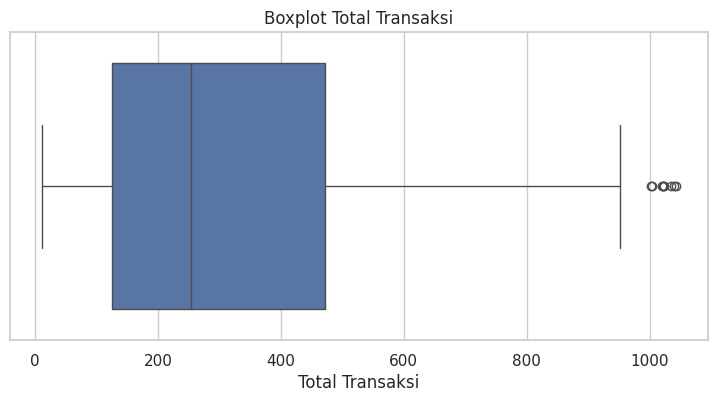

Q1: 124.422375
Q3: 471.35024999999996
IQR: 346.927875
Batas bawah: -395.9694375
Batas atas: 991.7420625
Jumlah outlier: 9


,Invoice ID,City,Product line,Total
166,234-65-2137,Naypyitaw,Home and lifestyle,1003.590
167,687-47-8271,Yangon,Fashion accessories,1039.290
350,860-79-0874,Naypyitaw,Fashion accessories,1042.650
357,554-42-2417,Naypyitaw,Sports and travel,1002.120
422,271-88-8734,Naypyitaw,Fashion accessories,1020.705
557,283-26-5248,Naypyitaw,Food and beverages,1034.460
699,751-41-9720,Naypyitaw,Home and lifestyle,1023.750
792,744-16-7898,Mandalay,Home and lifestyle,1022.385
996,303-96-2227,Mandalay,Home and lifestyle,1022.490


Insight: outlier perlu diperiksa dan tidak otomatis berarti kesalahan data.


In [10]:
Q1 = df["Total"].quantile(0.25)
Q3 = df["Total"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = df[
    (df["Total"] < batas_bawah) |
    (df["Total"] > batas_atas)
].copy()

plt.figure(figsize=(9, 4))
sns.boxplot(x=df["Total"])
plt.title("Boxplot Total Transaksi")
plt.xlabel("Total Transaksi")
plt.show()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)
print("Jumlah outlier:", len(outlier))

display(
    outlier[["Invoice ID", "City", "Product line", "Total"]]
)

print("Insight: outlier perlu diperiksa dan tidak otomatis berarti kesalahan data.")


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

penjualan_kategori.sort_values().plot(
    kind="barh", ax=axes[0, 0]
)
axes[0, 0].set_title("Penjualan per Kategori")

axes[0, 1].plot(
    penjualan_bulanan.index,
    penjualan_bulanan.values,
    marker="o"
)
axes[0, 1].set_title("Tren Penjualan Bulanan")
axes[0, 1].tick_params(axis="x", rotation=45)

axes[1, 0].hist(df["Total"], bins=25, edgecolor="black")
axes[1, 0].set_title("Distribusi Transaksi")

sns.boxplot(x=df["Total"], ax=axes[1, 1])
axes[1, 1].set_title("Sebaran Transaksi")

fig.suptitle("DASHBOARD ANALISIS PENJUALAN SUPERMARKET")
plt.tight_layout()
plt.show()


In [12]:
laporan = f"""
LAPORAN REKOMENDASI BISNIS SUPERMARKET

Berdasarkan hasil analisis data penjualan supermarket, terdapat
{len(df)} transaksi dengan total penjualan sebesar
{total_penjualan:,.2f}. Rata-rata nilai transaksi adalah
{rata_transaksi:,.2f}, median transaksi sebesar
{median_transaksi:,.2f}, dan standar deviasi sebesar
{std_transaksi:,.2f}. Rating rata-rata pelanggan mencapai
{rating_rata:.2f} dari 10. Informasi ini memberikan gambaran
mengenai nilai transaksi dan penilaian pelanggan terhadap
pengalaman berbelanja mereka.

Kategori produk dengan penjualan tertinggi adalah
{kategori_terlaris}, dengan total penjualan sebesar
{penjualan_kategori.max():,.2f}. Supermarket disarankan
mempertahankan ketersediaan stok dan kualitas produk kategori
tersebut. Sebaliknya, kategori {kategori_terendah} memiliki
penjualan terendah, yaitu {penjualan_kategori.min():,.2f}.
Manajemen dapat mengevaluasi minat pelanggan, penempatan produk,
harga, serta efektivitas promosi sebelum menentukan strategi
penjualan berikutnya.

Dari sisi lokasi, kota {kota_teratas} mencatat penjualan
tertinggi sebesar {penjualan_kota.max():,.2f}. Perusahaan dapat
mempelajari pola pembelian pelanggan di kota tersebut dan
membandingkannya dengan kota lain. Promosi sebaiknya disesuaikan
dengan kebutuhan pelanggan dan kategori produk yang diminati.
Data penjualan bulanan juga dapat digunakan untuk merencanakan
waktu promosi dan mengatur persediaan secara lebih efektif.

Deteksi menggunakan metode Interquartile Range menemukan
{len(outlier)} transaksi yang berpotensi menjadi outlier.
Transaksi tersebut perlu diperiksa untuk memastikan kewajaran
nilainya. Outlier tidak otomatis merupakan kesalahan pencatatan
sehingga tidak boleh langsung dihapus tanpa pemeriksaan.

Secara keseluruhan, supermarket disarankan memantau penjualan,
jumlah barang terjual, rating pelanggan, dan keuntungan secara
berkala. Evaluasi rutin dapat membantu meningkatkan pelayanan,
mengurangi risiko kekurangan stok, dan menyusun strategi
pemasaran yang lebih tepat berdasarkan data.
"""

print(laporan)
print("\nJumlah kata:", len(laporan.split()))



LAPORAN REKOMENDASI BISNIS SUPERMARKET

Berdasarkan hasil analisis data penjualan supermarket, terdapat
1000 transaksi dengan total penjualan sebesar
322,966.75. Rata-rata nilai transaksi adalah
322.97, median transaksi sebesar
253.85, dan standar deviasi sebesar
245.89. Rating rata-rata pelanggan mencapai
6.97 dari 10. Informasi ini memberikan gambaran
mengenai nilai transaksi dan penilaian pelanggan terhadap
pengalaman berbelanja mereka.

Kategori produk dengan penjualan tertinggi adalah
Food and beverages, dengan total penjualan sebesar
56,144.84. Supermarket disarankan
mempertahankan ketersediaan stok dan kualitas produk kategori
tersebut. Sebaliknya, kategori Health and beauty memiliki
penjualan terendah, yaitu 49,193.74.
Manajemen dapat mengevaluasi minat pelanggan, penempatan produk,
harga, serta efektivitas promosi sebelum menentukan strategi
penjualan berikutnya.

Dari sisi lokasi, kota Naypyitaw mencatat penjualan
tertinggi sebesar 110,568.71. Perusahaan dapat
mempelajari po